<a href="https://colab.research.google.com/github/theoldestsonbe/Business-Canvas/blob/main/Group_03_TK4_Deep_Learning_Application.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **1 — Import library dan download file dari GitHub**

In [ ]:
import urllib.request
from pathlib import Path
from collections import Counter
import random
import re
import math
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

# Folder penyimpanan proyek
PROJECT_DIR = Path("/content/machine_translation")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = PROJECT_DIR / "tk4_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# url sesuai soal
FILES = {
    "tutorial": (
        "https://raw.githubusercontent.com/n-patricia/comp6940/main/tutorial/sess9/seq2seq.ipynb",
        PROJECT_DIR / "seq2seq_tutorial.ipynb"
    ),
    "dataset": (
        "https://raw.githubusercontent.com/n-patricia/comp6940/main/data/eng-indo.txt",
        PROJECT_DIR / "eng-indo.txt"
    ),
    "transformer": (
        "https://raw.githubusercontent.com/n-patricia/comp6940/main/src/models/seq2seq.py",
        PROJECT_DIR / "seq2seq_transformer.py"
    )
}

# Download file jika belum tersedia
for name, (url, path) in FILES.items():
    if not path.exists():
        urllib.request.urlretrieve(url, path)

    print(f"{name}: {path}")

# Mengatur random seed supaya eksperimen lebih konsisten
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Menentukan perangkat komputasi
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nPyTorch:", torch.__version__)
print("Device:", device)
print("Semua file berhasil disiapkan.")

tutorial: /content/machine_translation/seq2seq_tutorial.ipynb
dataset: /content/machine_translation/eng-indo.txt
transformer: /content/machine_translation/seq2seq_transformer.py

PyTorch: 2.11.0+cu130
Device: cuda
Semua file berhasil disiapkan.


### **2 — Membaca data, preprocessing, vocabulary, dan DataLoader**

Kami membaca pasangan Inggris–Indonesia yang dipisahkan tab, mengubah huruf menjadi lowercase, lalu memisahkan kata dan tanda baca dengan tokenisasi berbasis ekspresi reguler. Angka dan tanda baca tetap dipertahankan agar informasi seperti jumlah dan bentuk pertanyaan dapat dipelajari.

Batas panjang adalah **20 token termasuk `<sos>` dan `<eos>`**, sehingga kalimat yang diterima memuat paling banyak 18 token teks pada setiap bahasa. Pasangan yang melampaui batas disaring sebelum pembagian data. Data diacak dengan seed 42 dan dibagi 90% untuk training serta 10% untuk validasi.

Vocabulary sumber dan target dibangun **hanya dari data training**. Token yang tidak ada dalam vocabulary dipetakan ke `<unk>`, sedangkan `<pad>` dipakai untuk menyamakan panjang batch. Pada eksekusi awal, 6.752 pasangan menjadi 6.707 setelah filtering: 6.036 training dan 671 validasi, dengan vocabulary Inggris 3.355 dan Indonesia 3.999 token termasuk token khusus.

In [ ]:
# ============================================================
# CELL 2: PREPROCESSING DAN PERSIAPAN DATASET
# ============================================================

DATA_PATH = PROJECT_DIR / "eng-indo.txt"

# Memisahkan kalimat Inggris dan Indonesia berdasarkan tab
raw_pairs = []

with open(DATA_PATH, "r", encoding="utf-8") as file:
    for line in file:
        parts = line.rstrip("\n").split("\t")

        if len(parts) >= 2:
            english = parts[0].strip().lower()
            indonesian = parts[1].strip().lower()

            if english and indonesian:
                raw_pairs.append((english, indonesian))

print("Jumlah pasangan data awal:", len(raw_pairs))

# Tokenisasi kata dan tanda baca
def tokenize(sentence):
    return re.findall(
        r"\w+|[^\w\s]",
        sentence.lower(),
        flags=re.UNICODE
    )

# Membatasi panjang kalimat untuk menyederhanakan eksperimen
MAX_LENGTH = 20

pairs = [
    (english, indonesian)
    for english, indonesian in raw_pairs
    if (
        len(tokenize(english)) + 2 <= MAX_LENGTH
        and len(tokenize(indonesian)) + 2 <= MAX_LENGTH
    )
]

# Mengacak data secara konsisten
random.Random(SEED).shuffle(pairs)

# Membagi 90% data training dan 10% data validasi
split_index = int(0.9 * len(pairs))

train_pairs = pairs[:split_index]
val_pairs = pairs[split_index:]

print("Data setelah filtering:", len(pairs))
print("Data training:", len(train_pairs))
print("Data validasi:", len(val_pairs))

# Melihat contoh data
print("\nContoh pasangan kalimat:")
for english, indonesian in raw_pairs[:5]:
    print("English   :", english)
    print("Indonesia :", indonesian)

# Token khusus
PAD_ID = 0
SOS_ID = 1
EOS_ID = 2
UNK_ID = 3

SPECIAL_TOKENS = [
    "<pad>", "<sos>", "<eos>", "<unk>"
]

# Membuat vocabulary dari data training saja
def build_vocab(sentences):
    counter = Counter()

    for sentence in sentences:
        counter.update(tokenize(sentence))

    itos = SPECIAL_TOKENS + [
        word for word, count in counter.most_common()
    ]

    stoi = {
        word: index
        for index, word in enumerate(itos)
    }

    return stoi, itos

# Vocabulary sumber dan target
src_stoi, src_itos = build_vocab(
    [english for english, _ in train_pairs]
)

tgt_stoi, tgt_itos = build_vocab(
    [indonesian for _, indonesian in train_pairs]
)

print("\nVocabulary Inggris:", len(src_itos))
print("Vocabulary Indonesia:", len(tgt_itos))

# Mengubah kalimat menjadi indeks numerik
def encode_sentence(sentence, vocab):
    tokens = tokenize(sentence)

    ids = [SOS_ID]
    ids += [
        vocab.get(word, UNK_ID)
        for word in tokens[:MAX_LENGTH - 2]
    ]
    ids += [EOS_ID]

    return ids

# Menyamakan panjang kalimat menggunakan padding
def encode_pairs(pairs):
    src_array = np.full(
        (len(pairs), MAX_LENGTH),
        PAD_ID,
        dtype=np.int64
    )

    tgt_array = np.full(
        (len(pairs), MAX_LENGTH),
        PAD_ID,
        dtype=np.int64
    )

    for i, (english, indonesian) in enumerate(pairs):
        src_ids = encode_sentence(english, src_stoi)
        tgt_ids = encode_sentence(indonesian, tgt_stoi)

        src_array[i, :len(src_ids)] = src_ids
        tgt_array[i, :len(tgt_ids)] = tgt_ids

    return (
        torch.tensor(src_array, dtype=torch.long),
        torch.tensor(tgt_array, dtype=torch.long)
    )

# Mengubah data training dan validasi menjadi tensor
train_src, train_tgt = encode_pairs(train_pairs)
val_src, val_tgt = encode_pairs(val_pairs)

# Membuat batch data
BATCH_SIZE = 64

train_dataset = TensorDataset(train_src, train_tgt)
val_dataset = TensorDataset(val_src, val_tgt)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nJumlah batch training:", len(train_loader))
print("Jumlah batch validasi:", len(val_loader))

Jumlah pasangan data awal: 6752
Data setelah filtering: 6707
Data training: 6036
Data validasi: 671

Contoh pasangan kalimat:
English   : run!
Indonesia : lari!
English   : who?
Indonesia : siapa?
English   : wow!
Indonesia : wow!
English   : help!
Indonesia : tolong!
English   : jump!
Indonesia : lompat!

Vocabulary Inggris: 3355
Vocabulary Indonesia: 3999

Jumlah batch training: 95
Jumlah batch validasi: 11


### **3 — Implementasi Model Seq2Seq (GRU + Attention) Tanpa Transformer**

Encoder GRU membaca urutan token Inggris dan menghasilkan representasi konteks. Decoder GRU menggunakan additive attention untuk memberi bobot pada posisi sumber saat memprediksi setiap token Indonesia. `pack_padded_sequence` membantu encoder mengabaikan padding, dan attention juga diberi padding mask.

Model ini kami buat dengan mengadaptasi tutorial, dengan perubahan pada bahasa sumber–target, preprocessing, batching, dan masking. Istilah **tanpa Transformer** pada soal di sini artinya menggunakan GRU + Attention. Namun baseline ini tetap menggunakan mekanisme attention.

In [ ]:
# Model baseline diadaptasi dari tutorial Seq2Seq:
# https://github.com/n-patricia/comp6940/blob/main/tutorial/sess9/seq2seq.ipynb
#
# Penyesuaian dilakukan pada preprocessing,
# penanganan padding, dan pemrosesan batch
# untuk dataset penerjemahan Inggris-Indonesia.

# Encoder: membaca urutan kata dalam bahasa Inggris
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p=0.1):
        super().__init__()

        self.embedding = nn.Embedding(
            input_size,
            hidden_size,
            padding_idx=PAD_ID
        )

        self.gru = nn.GRU(
            hidden_size,
            hidden_size,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout_p)

    def forward(self, src):
        embedded = self.dropout(self.embedding(src))

        # Menghitung panjang kalimat tanpa token padding
        lengths = (src != PAD_ID).sum(dim=1).cpu()

        # Menghindari pemrosesan token padding oleh GRU
        packed = pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, hidden = self.gru(packed)

        # Mengembalikan output ke panjang urutan semula
        outputs, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=src.size(1)
        )

        return outputs, hidden


# Additive Attention: memilih konteks input yang relevan
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()

        self.Wa = nn.Linear(hidden_size, hidden_size)
        self.Ua = nn.Linear(hidden_size, hidden_size)
        self.Va = nn.Linear(hidden_size, 1)

    def forward(self, query, keys, padding_mask=None):
        scores = self.Va(
            torch.tanh(self.Wa(query) + self.Ua(keys))
        ).squeeze(-1)

        # Mengabaikan posisi padding dalam attention
        if padding_mask is not None:
            scores = scores.masked_fill(
                padding_mask,
                -1e9
            )

        weights = F.softmax(scores, dim=-1).unsqueeze(1)

        context = torch.bmm(weights, keys)

        return context, weights


# Decoder: menghasilkan kata dalam bahasa Indonesia
class AttnDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1):
        super().__init__()

        self.embedding = nn.Embedding(
            output_size,
            hidden_size,
            padding_idx=PAD_ID
        )

        self.attention = AdditiveAttention(hidden_size)

        self.gru = nn.GRU(
            2 * hidden_size,
            hidden_size,
            batch_first=True
        )

        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward_step(
        self,
        input_token,
        hidden,
        encoder_outputs,
        src_padding_mask
    ):
        embedded = self.dropout(
            self.embedding(input_token)
        )

        query = hidden[-1].unsqueeze(1)

        context, attention_weights = self.attention(
            query,
            encoder_outputs,
            src_padding_mask
        )

        # Menggabungkan embedding token dan konteks attention
        gru_input = torch.cat(
            [embedded, context],
            dim=2
        )

        output, hidden = self.gru(gru_input, hidden)

        logits = self.out(output)

        return logits, hidden, attention_weights


# Menggabungkan encoder dan decoder menjadi model penerjemah
class Seq2SeqGRU(nn.Module):
    def __init__(
        self,
        src_vocab_size,
        tgt_vocab_size,
        hidden_size=128
    ):
        super().__init__()

        self.encoder = EncoderRNN(
            src_vocab_size,
            hidden_size
        )

        self.decoder = AttnDecoderRNN(
            hidden_size,
            tgt_vocab_size
        )

    def forward(self, src, tgt_input, src_padding_mask):
        encoder_outputs, hidden = self.encoder(src)

        outputs = []

        # Teacher forcing menggunakan token target sebelumnya
        for t in range(tgt_input.size(1)):
            logits, hidden, _ = self.decoder.forward_step(
                tgt_input[:, t:t + 1],
                hidden,
                encoder_outputs,
                src_padding_mask
            )

            outputs.append(logits)

        return torch.cat(outputs, dim=1)


# Membuat model baseline
HIDDEN_SIZE = 128

gru_model = Seq2SeqGRU(
    src_vocab_size=len(src_itos),
    tgt_vocab_size=len(tgt_itos),
    hidden_size=HIDDEN_SIZE
).to(device)

print("Model baseline berhasil dibuat.")
print(gru_model)

Model baseline berhasil dibuat.
Seq2SeqGRU(
  (encoder): EncoderRNN(
    (embedding): Embedding(3355, 128, padding_idx=0)
    (gru): GRU(128, 128, batch_first=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (decoder): AttnDecoderRNN(
    (embedding): Embedding(3999, 128, padding_idx=0)
    (attention): AdditiveAttention(
      (Wa): Linear(in_features=128, out_features=128, bias=True)
      (Ua): Linear(in_features=128, out_features=128, bias=True)
      (Va): Linear(in_features=128, out_features=1, bias=True)
    )
    (gru): GRU(256, 128, batch_first=True)
    (out): Linear(in_features=128, out_features=3999, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
)


### **4 — Implementasi model Transformer**

Transformer menggunakan self-attention dan positional encoding untuk memproses urutan. Konfigurasi eksperimen adalah 2 encoder layer, 2 decoder layer, embedding 128, 4 attention head, feedforward dimension 256, dan dropout 0,1. Script sumber dimuat langsung; import `Tensor` ditambahkan pada salinan lokal agar anotasi tipe dapat dibaca.

Causal mask membatasi decoder supaya tidak mengakses token target di masa depan. Padding mask digunakan saat training untuk mengabaikan posisi padding.

In [ ]:
# ============================================================
# LOAD DAN INISIALISASI MODEL TRANSFORMER
# Sumber:
# https://github.com/n-patricia/comp6940/blob/main/src/models/seq2seq.py
# ============================================================

import importlib.util
import sys
import urllib.request

# Menentukan lokasi script Transformer
TRANSFORMER_PATH = PROJECT_DIR / "seq2seq_transformer.py"

# Download script jika file belum tersedia
if not TRANSFORMER_PATH.exists():
    TRANSFORMER_URL = (
        "https://raw.githubusercontent.com/n-patricia/comp6940/"
        "main/src/models/seq2seq.py"
    )

    urllib.request.urlretrieve(
        TRANSFORMER_URL,
        TRANSFORMER_PATH
    )

# Membaca script asli dari GitHub
transformer_source = TRANSFORMER_PATH.read_text(
    encoding="utf-8"
)

# Memperbaiki import Tensor jika belum tersedia.
# Perbaikan ini diperlukan karena Tensor digunakan dalam
# anotasi tipe pada beberapa fungsi script.
if "from torch import Tensor" not in transformer_source:

    if "from torch.nn import Transformer" in transformer_source:
        transformer_source = transformer_source.replace(
            "from torch.nn import Transformer",
            "from torch.nn import Transformer\nfrom torch import Tensor",
            1
        )

    elif "import torch" in transformer_source:
        transformer_source = transformer_source.replace(
            "import torch",
            "import torch\nfrom torch import Tensor",
            1
        )

    else:
        transformer_source = (
            "from torch import Tensor\n" + transformer_source
        )

# Menyimpan perbaikan kompatibilitas pada salinan lokal.
# Arsitektur model tetap berasal dari script sumber.
TRANSFORMER_PATH.write_text(
    transformer_source,
    encoding="utf-8"
)

# Memuat file seq2seq.py sebagai modul Python
spec = importlib.util.spec_from_file_location(
    "seq2seq_transformer",
    TRANSFORMER_PATH
)

if spec is None or spec.loader is None:
    raise ImportError("Script Transformer gagal dimuat.")

transformer_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = transformer_module

spec.loader.exec_module(transformer_module)

# Mengambil kelas Transformer langsung dari script sumber
Seq2SeqTransformer = transformer_module.Seq2SeqTransformer

# Inisialisasi model dengan vocabulary Inggris-Indonesia
transformer_model = Seq2SeqTransformer(
    num_encoder_layers=2,
    num_decoder_layers=2,
    emb_size=128,
    nhead=4,
    src_vocab_size=len(src_itos),
    tgt_vocab_size=len(tgt_itos),
    dim_feedforward=256,
    dropout=0.1
).to(device)

# Menampilkan hasil inisialisasi
print("Script Transformer berhasil dimuat.")
print("Sumber:", TRANSFORMER_PATH)
print("Nama model:", transformer_model.__class__.__name__)
print("Device:", device)
print(transformer_model)

Script Transformer berhasil dimuat.
Sumber: /content/machine_translation/seq2seq_transformer.py
Nama model: Seq2SeqTransformer
Device: cuda
Seq2SeqTransformer(
  (transformer): Transformer(
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-1): 2 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=256, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=256, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
      (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    )
    (

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


### **5 — Training model baseline dan Transformer**

Kedua model memakai batch size 64, optimizer Adam, learning rate 0,001, dan gradient clipping 1,0. Loss yang digunakan adalah cross-entropy dengan padding diabaikan. Loss per epoch dihitung sebagai rata-rata berbobot jumlah token non-padding.

Input decoder digeser satu posisi dari target. Saat training dan penghitungan validation loss, decoder menerima token referensi sebelumnya (**teacher forcing**). Saat menerjemahkan, decoder menerima prediksinya sendiri, sehingga validation loss perlu dibaca bersama hasil terjemahan bebas.

Checkpoint terbaik masing-masing model kami simpan berdasarkan validation loss ketika sel training dijalankan. Model di memori tetap memuat bobot epoch terakhir supaya contoh terjemahan setelah training jelas berasal dari epoch terakhir.

In [ ]:
# ============================================================
# CELL 5: TRAINING DAN VALIDASI MODEL PENERJEMAH
# Tujuan: Membandingkan model tanpa Transformer dan dengan Transformer
# ============================================================

# Fungsi loss untuk menghitung kesalahan prediksi.
# Token padding diabaikan dalam perhitungan loss.
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)


# Membuat causal mask agar decoder Transformer
# tidak melihat token target di posisi berikutnya.
def generate_causal_mask(size):
    return torch.triu(
        torch.ones(size, size, dtype=torch.bool, device=device),
        diagonal=1
    )


# Fungsi untuk training atau validasi model selama satu epoch.
# Jika optimizer diberikan, model akan dilatih dan bobot diperbarui.
def run_epoch(model, loader, model_type, optimizer=None):

    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    total_tokens = 0

    for src_batch, tgt_batch in loader:
        src_batch = src_batch.to(device)
        tgt_batch = tgt_batch.to(device)

        # Input decoder dan target digeser satu posisi.
        tgt_input = tgt_batch[:, :-1]
        targets = tgt_batch[:, 1:]

        # Mask untuk mengabaikan padding pada kalimat sumber.
        src_padding_mask = src_batch.eq(PAD_ID)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):

            if model_type == "gru":

                # Forward pass model baseline GRU + Attention.
                logits = model(
                    src_batch,
                    tgt_input,
                    src_padding_mask
                )

            elif model_type == "transformer":

                # Transformer menggunakan format [sequence, batch].
                src_seq = src_batch.transpose(0, 1)
                tgt_seq = tgt_input.transpose(0, 1)

                # Membuat mask agar decoder tidak melihat token masa depan.
                tgt_mask = generate_causal_mask(tgt_seq.size(0))

                # Mask untuk padding pada kalimat target.
                tgt_padding_mask = tgt_input.eq(PAD_ID)

                # Forward pass model Transformer.
                logits = model(
                    src_seq,
                    tgt_seq,
                    None,
                    tgt_mask,
                    src_padding_mask,
                    tgt_padding_mask,
                    src_padding_mask
                )

                # Mengubah output kembali ke format [batch, sequence, vocab].
                logits = logits.transpose(0, 1)

            else:
                raise ValueError("Jenis model tidak dikenal.")

            # Menghitung loss berdasarkan prediksi token target.
            loss = criterion(
                logits.reshape(-1, len(tgt_itos)),
                targets.reshape(-1)
            )

            if is_training:
                # Menghitung gradien dan memperbarui bobot model.
                loss.backward()

                # Membantu menjaga kestabilan gradien selama training.
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        # Menghitung loss berdasarkan jumlah token selain padding.
        valid_tokens = (targets != PAD_ID).sum().item()
        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

    return total_loss / max(total_tokens, 1)


# ============================================================
# KONFIGURASI TRAINING
# ============================================================

EPOCHS = 20
LEARNING_RATE = 0.001

# Menyimpan training loss dan validation loss setiap epoch.
# Data ini akan digunakan untuk membuat grafik perbandingan.
history = {
    "GRU_train": [],
    "GRU_val": [],
    "Transformer_train": [],
    "Transformer_val": []
}

# Optimizer untuk masing-masing model.
gru_optimizer = optim.Adam(
    gru_model.parameters(),
    lr=LEARNING_RATE
)

transformer_optimizer = optim.Adam(
    transformer_model.parameters(),
    lr=LEARNING_RATE
)


# Menyimpan bobot terbaik hanya dari epoch yang benar-benar dijalankan.
best_validation = {"gru": float("inf"), "transformer": float("inf")}
best_checkpoint_info = {}

def save_best_checkpoint(model, optimizer, model_type, epoch, val_loss):
    if val_loss >= best_validation[model_type]:
        return
    best_validation[model_type] = val_loss
    checkpoint_path = OUTPUT_DIR / f"checkpoint_{model_type}_best.pt"
    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "model_type": model_type,
        "epoch": epoch,
        "validation_loss": val_loss,
        "src_itos": src_itos,
        "tgt_itos": tgt_itos,
        "config": {
            "seed": SEED, "max_length": MAX_LENGTH,
            "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
            "epochs": EPOCHS, "hidden_size": HIDDEN_SIZE,
            "transformer": {"num_encoder_layers": 2, "num_decoder_layers": 2,
                            "emb_size": 128, "nhead": 4,
                            "dim_feedforward": 256, "dropout": 0.1},
            "tokenizer_pattern": r"\w+|[^\w\s]",
            "special_tokens": SPECIAL_TOKENS,
        },
    }, checkpoint_path)
    best_checkpoint_info[model_type] = {
        "epoch": epoch, "validation_loss": val_loss,
        "path": str(checkpoint_path),
    }

# ============================================================
# A. TRAINING MODEL BASELINE GRU + ATTENTION
# ============================================================
# Model ini dilatih sebagai pembanding sebelum menggunakan Transformer.
# Hasil loss disimpan untuk dibandingkan dengan model Transformer.

print("TRAINING MODEL BASELINE GRU + ATTENTION")

for epoch in range(1, EPOCHS + 1):

    # Melatih baseline menggunakan data training.
    train_loss = run_epoch(
        gru_model,
        train_loader,
        "gru",
        optimizer=gru_optimizer
    )

    # Mengevaluasi baseline menggunakan data validasi.
    val_loss = run_epoch(
        gru_model,
        val_loader,
        "gru"
    )

    # Menyimpan hasil loss pada setiap epoch.
    history["GRU_train"].append(train_loss)
    history["GRU_val"].append(val_loss)
    save_best_checkpoint(gru_model, gru_optimizer, "gru", epoch, val_loss)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Training Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )


# ============================================================
# B. TRAINING MODEL TRANSFORMER
# ============================================================
# Model Transformer dilatih menggunakan dataset Inggris-Indonesia
# yang sama dengan baseline agar hasilnya dapat dibandingkan.

print("\nTRAINING MODEL TRANSFORMER")

for epoch in range(1, EPOCHS + 1):

    # Melatih model Transformer menggunakan data training.
    train_loss = run_epoch(
        transformer_model,
        train_loader,
        "transformer",
        optimizer=transformer_optimizer
    )

    # Mengevaluasi model Transformer menggunakan data validasi.
    val_loss = run_epoch(
        transformer_model,
        val_loader,
        "transformer"
    )

    # Menyimpan hasil loss untuk grafik perbandingan.
    history["Transformer_train"].append(train_loss)
    history["Transformer_val"].append(val_loss)
    save_best_checkpoint(transformer_model, transformer_optimizer, "transformer", epoch, val_loss)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Training Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )


# Menandakan seluruh proses training kedua model telah selesai.
print("\nTraining kedua model selesai!")

TRAINING MODEL BASELINE GRU + ATTENTION
Epoch 1/20 | Training Loss: 5.6445 | Validation Loss: 4.9217
Epoch 2/20 | Training Loss: 4.6388 | Validation Loss: 4.5301
Epoch 3/20 | Training Loss: 4.2527 | Validation Loss: 4.2808
Epoch 4/20 | Training Loss: 3.9443 | Validation Loss: 4.0787
Epoch 5/20 | Training Loss: 3.6647 | Validation Loss: 3.9141
Epoch 6/20 | Training Loss: 3.4140 | Validation Loss: 3.8018
Epoch 7/20 | Training Loss: 3.1919 | Validation Loss: 3.7099
Epoch 8/20 | Training Loss: 2.9921 | Validation Loss: 3.6116
Epoch 9/20 | Training Loss: 2.8036 | Validation Loss: 3.5380
Epoch 10/20 | Training Loss: 2.6306 | Validation Loss: 3.4993
Epoch 11/20 | Training Loss: 2.4723 | Validation Loss: 3.4512
Epoch 12/20 | Training Loss: 2.3174 | Validation Loss: 3.4193
Epoch 13/20 | Training Loss: 2.1786 | Validation Loss: 3.3884
Epoch 14/20 | Training Loss: 2.0464 | Validation Loss: 3.3713
Epoch 15/20 | Training Loss: 1.9172 | Validation Loss: 3.3506
Epoch 16/20 | Training Loss: 1.8037 | V

### **6 — Plot fungsi kerugian**

Garis training menunjukkan kemampuan model menyesuaikan data pelatihan, sedangkan garis validasi menunjukkan loss pada data yang tidak dipakai memperbarui bobot. Training loss yang terus turun bersama validation loss yang meningkat merupakan indikasi overfitting. Grafik kami buat menampilkan seluruh epoch supaya perubahan ini terlihat.

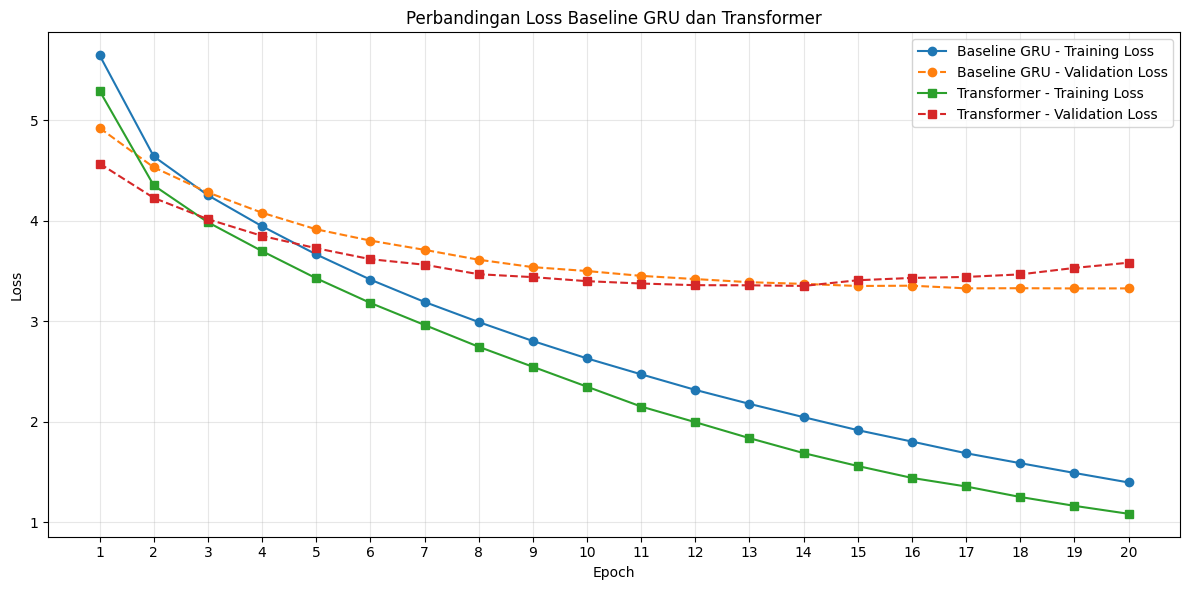

In [ ]:
# ============================================================
# PLOT PERBANDINGAN LOSS TANPA VS TRANSFORMER
# ============================================================

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 6))

# Loss model baseline
plt.plot(
    epochs_range,
    history["GRU_train"],
    marker="o",
    label="Baseline GRU - Training Loss"
)

plt.plot(
    epochs_range,
    history["GRU_val"],
    marker="o",
    linestyle="--",
    label="Baseline GRU - Validation Loss"
)

# Loss model Transformer
plt.plot(
    epochs_range,
    history["Transformer_train"],
    marker="s",
    label="Transformer - Training Loss"
)

plt.plot(
    epochs_range,
    history["Transformer_val"],
    marker="s",
    linestyle="--",
    label="Transformer - Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Perbandingan Loss Baseline GRU dan Transformer")

plt.xticks(list(epochs_range))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Menyimpan plot
plt.savefig(
    "/content/loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### **7 — Menguji hasil terjemahan**

Kedua fungsi memakai **greedy decoding**, yaitu memilih token berprobabilitas paling tinggi pada setiap langkah sampai `<eos>` atau batas panjang tercapai. Pengujian berikut menggunakan lima pasangan validasi yang sama untuk kedua model dan bobot epoch terakhir. Namun yang perlu dicatat adalah contoh ini bersifat kualitatif dan belum mewakili keseluruhan kualitas terjemahan.

In [ ]:
# Penerjemah menggunakan model baseline
def translate_gru(sentence):
    gru_model.eval()

    ids = encode_sentence(sentence, src_stoi)

    src = torch.tensor(
        ids,
        dtype=torch.long,
        device=device
    ).unsqueeze(0)

    src_padding_mask = src.eq(PAD_ID)
    translated_words = []

    with torch.no_grad():
        encoder_outputs, hidden = gru_model.encoder(src)

        token = torch.tensor(
            [[SOS_ID]],
            dtype=torch.long,
            device=device
        )

        for _ in range(MAX_LENGTH - 1):

            logits, hidden, _ = gru_model.decoder.forward_step(
                token,
                hidden,
                encoder_outputs,
                src_padding_mask
            )

            next_id = logits.argmax(dim=-1).item()

            if next_id == EOS_ID:
                break

            if next_id not in (PAD_ID, SOS_ID):
                translated_words.append(tgt_itos[next_id])

            token = torch.tensor(
                [[next_id]],
                dtype=torch.long,
                device=device
            )

    return " ".join(translated_words)


# Penerjemah menggunakan model Transformer
def translate_transformer(sentence):
    transformer_model.eval()

    ids = encode_sentence(sentence, src_stoi)

    # Bentuk input Transformer: [sequence, batch]
    src = torch.tensor(
        ids,
        dtype=torch.long,
        device=device
    ).unsqueeze(1)

    translated_words = []

    with torch.no_grad():
        memory = transformer_model.encode(src, None)

        tgt = torch.tensor(
            [[SOS_ID]],
            dtype=torch.long,
            device=device
        )

        for _ in range(MAX_LENGTH - 1):

            tgt_mask = generate_causal_mask(
                tgt.size(0)
            )

            decoder_output = transformer_model.decode(
                tgt,
                memory,
                tgt_mask
            )

            logits = transformer_model.generator(
                decoder_output[-1]
            )

            next_id = logits.argmax(dim=-1).item()

            if next_id == EOS_ID:
                break

            if next_id not in (PAD_ID, SOS_ID):
                translated_words.append(tgt_itos[next_id])

            next_token = torch.tensor(
                [[next_id]],
                dtype=torch.long,
                device=device
            )

            tgt = torch.cat(
                [tgt, next_token],
                dim=0
            )

    return " ".join(translated_words)


# Membandingkan lima contoh hasil penerjemahan
for english, reference in val_pairs[:5]:

    prediction_gru = translate_gru(english)
    prediction_transformer = translate_transformer(english)

    print("English              :", english)
    print("Terjemahan referensi :", reference)
    print("Prediksi baseline    :", prediction_gru)
    print("Prediksi Transformer :", prediction_transformer)
    print("-" * 70)

English              : the station is 100 meters away.
Terjemahan referensi : stasiunnya terletak 100 meter dari sini.
Prediksi baseline    : stasiunnya berjarak dari kolong meja .
Prediksi Transformer : stasiunnya terletak 2 mil dari stasiun .
----------------------------------------------------------------------
English              : everything i've told you may not be true.
Terjemahan referensi : semua yang telah aku beritahukan padamu mungkin tidak sepenuhnya benar.
Prediksi baseline    : semuanya aku bisa melakukannya .
Prediksi Transformer : aku tidak tahu kalau kau mungkin saja .
----------------------------------------------------------------------
English              : why didn't she come?
Terjemahan referensi : kenapa dia tidak datang?
Prediksi baseline    : kenapa dia datang ?
Prediksi Transformer : kenapa dia tidak datang ?
----------------------------------------------------------------------
English              : i'm glad i could help.
Terjemahan referensi : saya senan

### **8 — Ringkasan dan pembahasan hasil**

Tabel dinamis berikut ini menggunakan riwayat training yang aktif. Untuk laporan eksekusi awal, angka pada pembahasan setelah tabel berasal dari log yang sudah tersimpan di notebook.

In [ ]:
# Ringkasan dihitung ulang dari history yang tersedia setelah training.
import pandas as pd

summary_rows = []
for name, prefix, model in [
    ("GRU + Attention", "GRU", gru_model),
    ("Transformer", "Transformer", transformer_model),
]:
    train_losses = history[f"{prefix}_train"]
    val_losses = history[f"{prefix}_val"]
    best_index = int(np.argmin(val_losses))
    summary_rows.append({
        "Model": name,
        "Parameter trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "Epoch terbaik": best_index + 1,
        "Validation loss terbaik": val_losses[best_index],
        "Training loss terakhir": train_losses[-1],
        "Validation loss terakhir": val_losses[-1],
        "Gap val-train terakhir": val_losses[-1] - train_losses[-1],
    })
summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

          Model  Parameter trainable  Epoch terbaik  Validation loss terbaik  Training loss terakhir  Validation loss terakhir  Gap val-train terakhir
GRU + Attention              1737632             19                   3.3262                  1.3972                    3.3267                  1.9295
    Transformer              2120223             14                   3.3511                  1.0856                    3.5821                  2.4965
